In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("insurance_dataset.csv")

print("First 5 rows:")
display(df.head())

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

First 5 rows:


,age,gender,bmi,children,smoker,region,medical_history,family_medical_history,exercise_frequency,occupation,coverage_level,charges
0,46,male,21.45,5,yes,southeast,Diabetes,NaN,Never,Blue collar,Premium,20460.307669
1,25,female,25.38,2,yes,northwest,Diabetes,High blood pressure,Occasionally,White collar,Premium,20390.899218
2,38,male,44.88,2,yes,southwest,NaN,High blood pressure,Occasionally,Blue collar,Premium,20204.476302
3,25,male,19.89,0,no,northwest,NaN,Diabetes,Rarely,White collar,Standard,11789.029843
4,49,male,38.21,3,yes,northwest,Diabetes,High blood pressure,Rarely,White collar,Standard,19268.309838


Dataset shape: (1000000, 12)

Column names:
['age', 'gender', 'bmi', 'children', 'smoker', 'region', 'medical_history', 'family_medical_history', 'exercise_frequency', 'occupation', 'coverage_level', 'charges']

Data types:
age                         int64
gender                     object
bmi                       float64
children                    int64
smoker                     object
region                     object
medical_history            object
family_medical_history     object
exercise_frequency         object
occupation                 object
coverage_level             object
charges                   float64
dtype: object


In [3]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:")
print(df.isnull().sum().sum())

Missing values in each column:
age                            0
gender                         0
bmi                            0
children                       0
smoker                         0
region                         0
medical_history           250762
family_medical_history    250404
exercise_frequency             0
occupation                     0
coverage_level                 0
charges                        0
dtype: int64

Total missing values:
501166


In [4]:
print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().copy()

print("Dataset shape after removing duplicates:", df.shape)

Duplicate rows: 0
Dataset shape after removing duplicates: (1000000, 12)


In [5]:
# Fill missing categorical values
categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns

for col in categorical_columns:
    df[col] = df[col].fillna("Unknown")

# Fill missing numerical values with the median
numerical_columns = df.select_dtypes(
    include=np.number
).columns

for col in numerical_columns:
    if df[col].notna().any():
        df[col] = df[col].fillna(df[col].median())

print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
age                       0
gender                    0
bmi                       0
children                  0
smoker                    0
region                    0
medical_history           0
family_medical_history    0
exercise_frequency        0
occupation                0
coverage_level            0
charges                   0
dtype: int64


In [6]:
# Identify numerical and categorical columns
numerical_columns = df.select_dtypes(
    include=np.number
).columns.tolist()

categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical columns:")
print(numerical_columns)

print("\nCategorical columns:")
print(categorical_columns)

# Convert categorical columns into numerical columns
df_encoded = pd.get_dummies(
    df,
    columns=categorical_columns,
    dtype=int
)

print("\nPreprocessed dataset:")
display(df_encoded.head())

print("Encoded dataset shape:", df_encoded.shape)

Numerical columns:
['age', 'bmi', 'children', 'charges']

Categorical columns:
['gender', 'smoker', 'region', 'medical_history', 'family_medical_history', 'exercise_frequency', 'occupation', 'coverage_level']

Preprocessed dataset:


,age,bmi,children,charges,gender_female,gender_male,smoker_no,smoker_yes,region_northeast,region_northwest,...,exercise_frequency_Never,exercise_frequency_Occasionally,exercise_frequency_Rarely,occupation_Blue collar,occupation_Student,occupation_Unemployed,occupation_White collar,coverage_level_Basic,coverage_level_Premium,coverage_level_Standard
0,46,21.45,5,20460.307669,0,1,0,1,0,0,...,1,0,0,1,0,0,0,0,1,0
1,25,25.38,2,20390.899218,1,0,0,1,0,1,...,0,1,0,0,0,0,1,0,1,0
2,38,44.88,2,20204.476302,0,1,0,1,0,0,...,0,1,0,1,0,0,0,0,1,0
3,25,19.89,0,11789.029843,0,1,1,0,0,1,...,0,0,1,0,0,0,1,0,0,1
4,49,38.21,3,19268.309838,0,1,0,1,0,1,...,0,0,1,0,0,0,1,0,0,1


Encoded dataset shape: (1000000, 31)


In [7]:
df.to_csv("insurance_cleaned.csv", index=False)

df_encoded.to_csv("insurance_preprocessed.csv", index=False)

print("Cleaned dataset saved successfully.")
print("Preprocessed dataset saved successfully.")

Cleaned dataset saved successfully.
Preprocessed dataset saved successfully.


In [8]:
print("Summary Statistics:")
display(df[numerical_columns].describe())

Summary Statistics:


,age,bmi,children,charges
count,1000000.000000,1000000.000000,1000000.000000,1000000.000000
mean,41.495282,34.001839,2.499886,16735.117481
std,13.855189,9.231680,1.707679,4415.808211
min,18.000000,18.000000,0.000000,3445.011643
25%,29.000000,26.020000,1.000000,13600.372379
50%,41.000000,34.000000,2.000000,16622.127973
75%,53.000000,41.990000,4.000000,19781.465410
max,65.000000,50.000000,5.000000,32561.560374


In [9]:
print("Mean:")
print(df[numerical_columns].mean())

Mean:
age            41.495282
bmi            34.001839
children        2.499886
charges     16735.117481
dtype: float64


In [10]:
print("Median:")
print(df[numerical_columns].median())

Median:
age            41.000000
bmi            34.000000
children        2.000000
charges     16622.127973
dtype: float64


In [11]:
print("Mode:")
display(df.mode().iloc[[0]])

Mode:


,age,gender,bmi,children,smoker,region,medical_history,family_medical_history,exercise_frequency,occupation,coverage_level,charges
0,43.0,male,46.17,3.0,yes,northeast,Unknown,Unknown,Rarely,Unemployed,Basic,3445.011643


In [12]:
print("Variance:")
print(df[numerical_columns].var())

Variance:
age         1.919663e+02
bmi         8.522392e+01
children    2.916167e+00
charges     1.949936e+07
dtype: float64


In [13]:
print("Standard Deviation:")
print(df[numerical_columns].std())

Standard Deviation:
age           13.855189
bmi            9.231680
children       1.707679
charges     4415.808211
dtype: float64


In [14]:
print("Quartiles:")

display(
    df[numerical_columns].quantile([0.25, 0.50, 0.75])
)

Quartiles:


,age,bmi,children,charges
0.25,29.0,26.02,1.0,13600.372379
0.50,41.0,34.00,2.0,16622.127973
0.75,53.0,41.99,4.0,19781.465410


In [15]:
print("Minimum values:")
print(df[numerical_columns].min())

print("\nMaximum values:")
print(df[numerical_columns].max())

Minimum values:
age           18.000000
bmi           18.000000
children       0.000000
charges     3445.011643
dtype: float64

Maximum values:
age            65.000000
bmi            50.000000
children        5.000000
charges     32561.560374
dtype: float64


In [16]:
print("Correlation Matrix:")

display(df[numerical_columns].corr())

Correlation Matrix:


,age,bmi,children,charges
age,1.000000,0.001428,-0.001317,0.063390
bmi,0.001428,1.000000,-0.001635,0.104429
children,-0.001317,-0.001635,1.000000,0.076801
charges,0.063390,0.104429,0.076801,1.000000


In [17]:
for col in categorical_columns:
    print("\nFrequency distribution of", col)
    print(df[col].value_counts())


Frequency distribution of gender
gender
male      500107
female    499893
Name: count, dtype: int64

Frequency distribution of smoker
smoker
yes    500129
no     499871
Name: count, dtype: int64

Frequency distribution of region
region
northeast    250343
southwest    250095
northwest    249931
southeast    249631
Name: count, dtype: int64

Frequency distribution of medical_history
medical_history
Unknown                250762
Heart disease          250121
High blood pressure    249782
Diabetes               249335
Name: count, dtype: int64

Frequency distribution of family_medical_history
family_medical_history
Unknown                250404
Heart disease          250035
High blood pressure    249824
Diabetes               249737
Name: count, dtype: int64

Frequency distribution of exercise_frequency
exercise_frequency
Rarely          250538
Occasionally    250362
Frequently      249746
Never           249354
Name: count, dtype: int64

Frequency distribution of occupation
occupation
U

In [18]:
for col in numerical_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print("\nColumn:", col)
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Number of Outliers:", len(outliers))


Column: age
Lower Bound: -7.0
Upper Bound: 89.0
Number of Outliers: 0

Column: bmi
Lower Bound: 2.064999999999994
Upper Bound: 65.94500000000001
Number of Outliers: 0

Column: children
Lower Bound: -3.5
Upper Bound: 8.5
Number of Outliers: 0

Column: charges
Lower Bound: 4328.732831619773
Upper Bound: 29053.104957406984
Number of Outliers: 2217


In [19]:
plot_df = df.sample(
    n=min(10000, len(df)),
    random_state=42
)

print("Sample shape:", plot_df.shape)

Sample shape: (10000, 12)


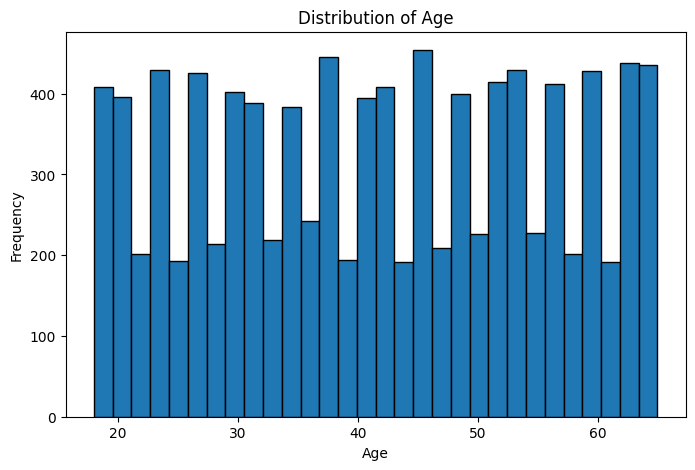

In [20]:
# Ensure plot_df is defined by sampling the dataset
plot_df = df.sample(
    n=min(10000, len(df)),
    random_state=42
)

plt.figure(figsize=(8, 5))

plt.hist(
    plot_df["age"],
    bins=30,
    edgecolor="black"
)

plt.title("Distribution of Age")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.show()

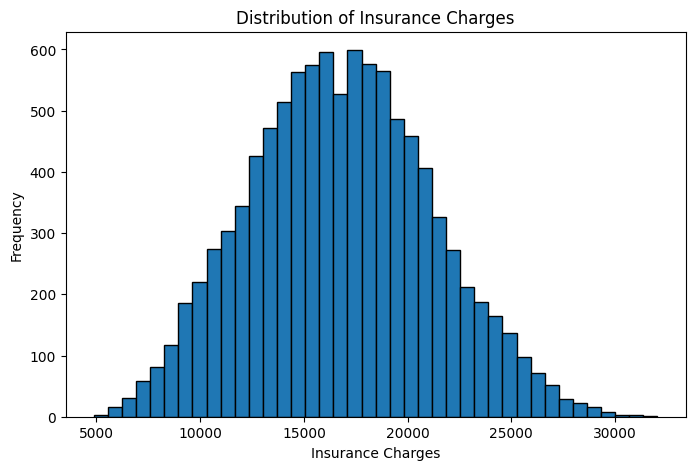

In [21]:
plt.figure(figsize=(8, 5))

plt.hist(
    plot_df["charges"],
    bins=40,
    edgecolor="black"
)

plt.title("Distribution of Insurance Charges")
plt.xlabel("Insurance Charges")
plt.ylabel("Frequency")

plt.show()

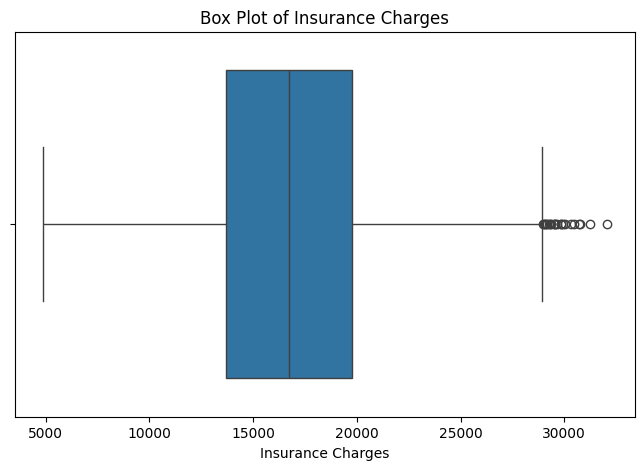

In [22]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=plot_df["charges"])

plt.title("Box Plot of Insurance Charges")
plt.xlabel("Insurance Charges")

plt.show()

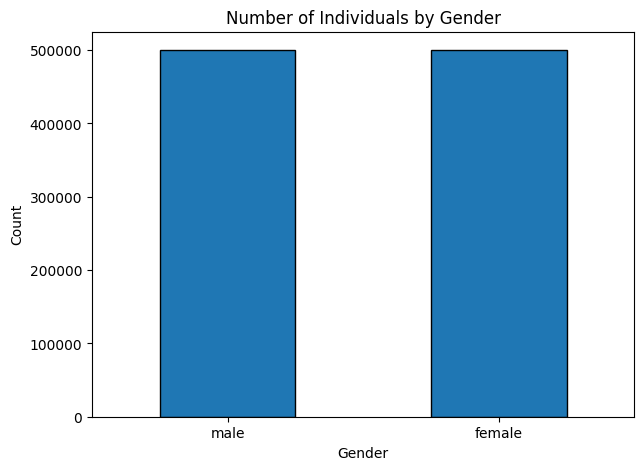

In [23]:
gender_counts = df["gender"].value_counts()

plt.figure(figsize=(7, 5))

gender_counts.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Number of Individuals by Gender")
plt.xlabel("Gender")
plt.ylabel("Count")

plt.xticks(rotation=0)
plt.show()

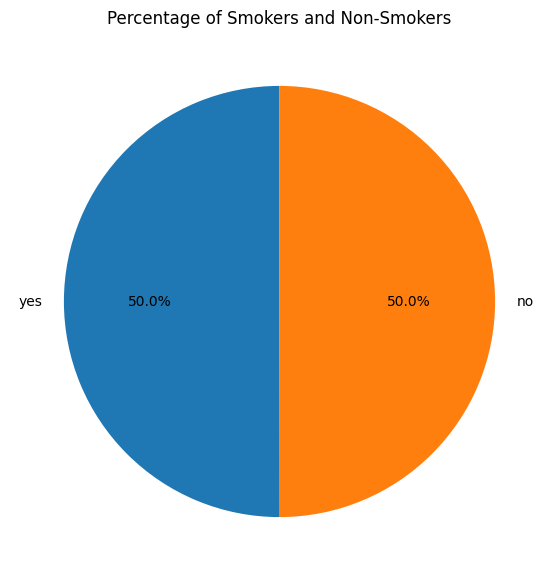

In [24]:
smoker_counts = df["smoker"].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    smoker_counts,
    labels=smoker_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Percentage of Smokers and Non-Smokers")

plt.show()

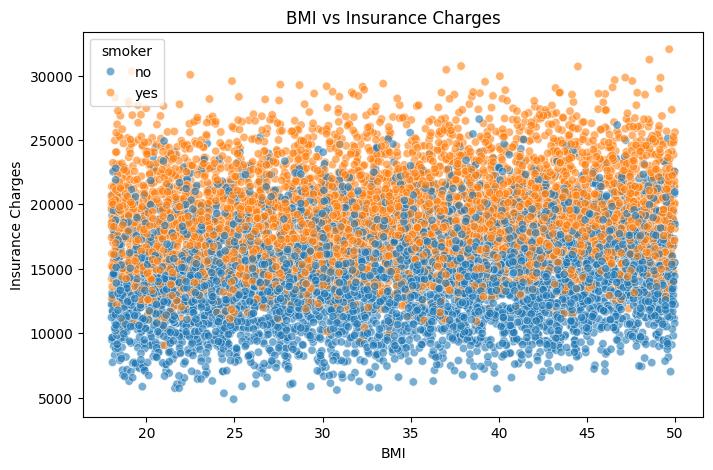

In [25]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=plot_df,
    x="bmi",
    y="charges",
    hue="smoker",
    alpha=0.6
)

plt.title("BMI vs Insurance Charges")
plt.xlabel("BMI")
plt.ylabel("Insurance Charges")

plt.show()

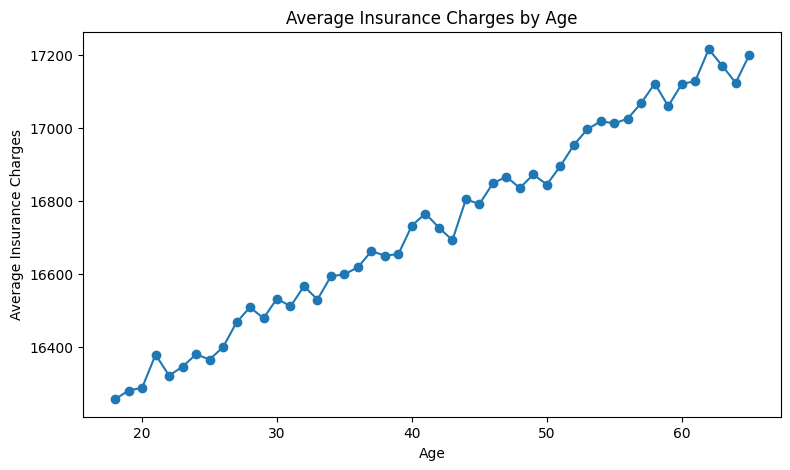

In [26]:
age_charges = df.groupby("age")["charges"].mean()

plt.figure(figsize=(9, 5))

plt.plot(
    age_charges.index,
    age_charges.values,
    marker="o"
)

plt.title("Average Insurance Charges by Age")
plt.xlabel("Age")
plt.ylabel("Average Insurance Charges")

plt.show()

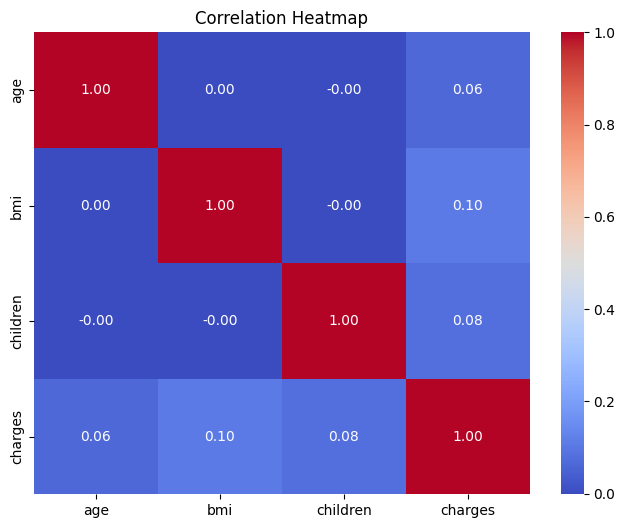

In [27]:
plt.figure(figsize=(8, 6))

correlation = df[numerical_columns].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

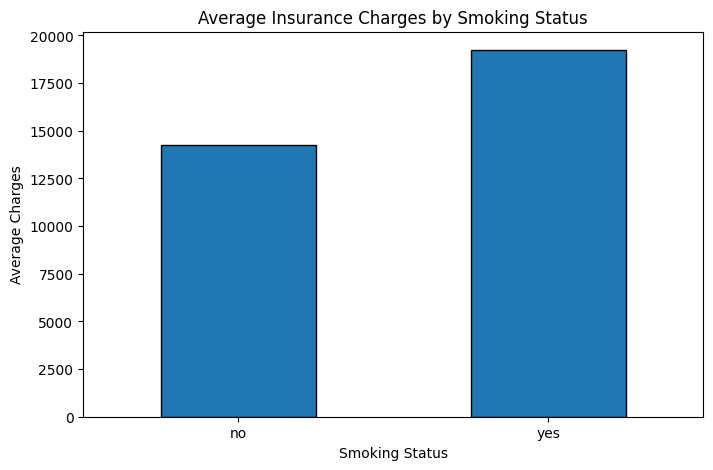

In [28]:
smoker_charges = df.groupby("smoker")["charges"].mean()

plt.figure(figsize=(8, 5))

smoker_charges.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Average Insurance Charges by Smoking Status")
plt.xlabel("Smoking Status")
plt.ylabel("Average Charges")

plt.xticks(rotation=0)
plt.show()

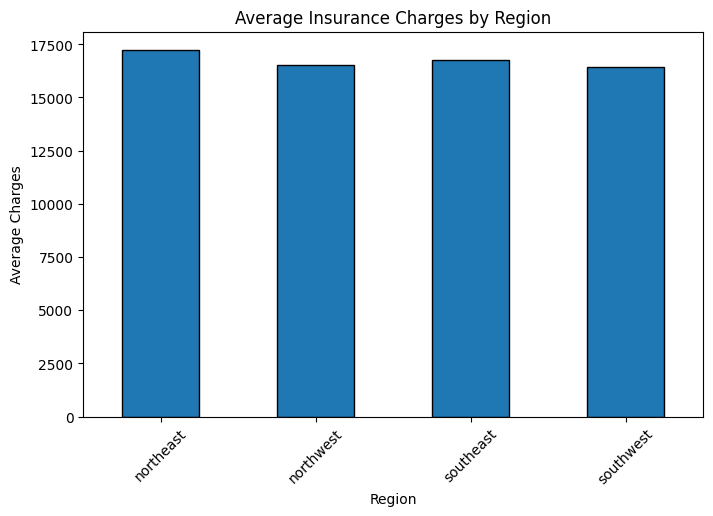

In [29]:
region_charges = df.groupby("region")["charges"].mean()

plt.figure(figsize=(8, 5))

region_charges.plot(
    kind="bar",
    edgecolor="black"
)

plt.title("Average Insurance Charges by Region")
plt.xlabel("Region")
plt.ylabel("Average Charges")

plt.xticks(rotation=45)
plt.show()

In [30]:
print("DATA ANALYSIS COMPLETED SUCCESSFULLY")

print("\nFinal dataset shape:")
print(df.shape)

print("\nFinal summary statistics:")
display(df[numerical_columns].describe())

print("\nGenerated visualizations:")
print("1. Histogram of age")
print("2. Histogram of insurance charges")
print("3. Box plot of insurance charges")
print("4. Bar chart of gender")
print("5. Pie chart of smoking status")
print("6. Scatter plot of BMI vs charges")
print("7. Line chart of average charges by age")
print("8. Correlation heatmap")
print("9. Average charges by smoking status")
print("10. Average charges by region")

DATA ANALYSIS COMPLETED SUCCESSFULLY

Final dataset shape:
(1000000, 12)

Final summary statistics:


,age,bmi,children,charges
count,1000000.000000,1000000.000000,1000000.000000,1000000.000000
mean,41.495282,34.001839,2.499886,16735.117481
std,13.855189,9.231680,1.707679,4415.808211
min,18.000000,18.000000,0.000000,3445.011643
25%,29.000000,26.020000,1.000000,13600.372379
50%,41.000000,34.000000,2.000000,16622.127973
75%,53.000000,41.990000,4.000000,19781.465410
max,65.000000,50.000000,5.000000,32561.560374



Generated visualizations:
1. Histogram of age
2. Histogram of insurance charges
3. Box plot of insurance charges
4. Bar chart of gender
5. Pie chart of smoking status
6. Scatter plot of BMI vs charges
7. Line chart of average charges by age
8. Correlation heatmap
9. Average charges by smoking status
10. Average charges by region


In [31]:
%pip install pandas numpy scikit-learn matplotlib seaborn joblib streamlit

In [32]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [33]:
df = pd.read_csv("insurance_dataset.csv")

print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nDataset columns:")
print(df.columns.tolist())

Dataset shape: (1000000, 12)

First 5 rows:


,age,gender,bmi,children,smoker,region,medical_history,family_medical_history,exercise_frequency,occupation,coverage_level,charges
0,46,male,21.45,5,yes,southeast,Diabetes,NaN,Never,Blue collar,Premium,20460.307669
1,25,female,25.38,2,yes,northwest,Diabetes,High blood pressure,Occasionally,White collar,Premium,20390.899218
2,38,male,44.88,2,yes,southwest,NaN,High blood pressure,Occasionally,Blue collar,Premium,20204.476302
3,25,male,19.89,0,no,northwest,NaN,Diabetes,Rarely,White collar,Standard,11789.029843
4,49,male,38.21,3,yes,northwest,Diabetes,High blood pressure,Rarely,White collar,Standard,19268.309838



Dataset columns:
['age', 'gender', 'bmi', 'children', 'smoker', 'region', 'medical_history', 'family_medical_history', 'exercise_frequency', 'occupation', 'coverage_level', 'charges']


In [34]:
# Remove duplicate rows
df = df.drop_duplicates().copy()

# Convert target to numeric
df["charges"] = pd.to_numeric(
    df["charges"],
    errors="coerce"
)

# Remove rows with missing or invalid target values
df = df.dropna(subset=["charges"])

# Remove infinite target values
df = df[np.isfinite(df["charges"])].copy()

# Remove rows with no predictor information
df = df.dropna(
    subset=[col for col in df.columns if col != "charges"],
    how="all"
)

print("Dataset shape after cleaning:", df.shape)

print("\nMissing values:")
print(df.isnull().sum())

print("\nTarget statistics:")
print(df["charges"].describe())

Dataset shape after cleaning: (1000000, 12)

Missing values:
age                            0
gender                         0
bmi                            0
children                       0
smoker                         0
region                         0
medical_history           250762
family_medical_history    250404
exercise_frequency             0
occupation                     0
coverage_level                 0
charges                        0
dtype: int64

Target statistics:
count    1000000.000000
mean       16735.117481
std         4415.808211
min         3445.011643
25%        13600.372379
50%        16622.127973
75%        19781.465410
max        32561.560374
Name: charges, dtype: float64


In [35]:
target = "charges"

X = df.drop(columns=[target])
y = df[target]

print("Input features:")
print(X.columns.tolist())

print("\nTarget variable:", target)

print("\nNumber of input features:", X.shape[1])
print("Number of records:", X.shape[0])

Input features:
['age', 'gender', 'bmi', 'children', 'smoker', 'region', 'medical_history', 'family_medical_history', 'exercise_frequency', 'occupation', 'coverage_level']

Target variable: charges

Number of input features: 11
Number of records: 1000000


In [36]:
numerical_features = X.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Numerical features:")
print(numerical_features)

print("\nCategorical features:")
print(categorical_features)

Numerical features:
['age', 'bmi', 'children']

Categorical features:
['gender', 'smoker', 'region', 'medical_history', 'family_medical_history', 'exercise_frequency', 'occupation', 'coverage_level']


In [37]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])

Training records: 800000
Testing records: 200000


In [38]:
numerical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(handle_unknown="ignore")
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numerical_transformer,
            numerical_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [39]:
linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", LinearRegression())
    ]
)

linear_model.fit(X_train, y_train)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [40]:
linear_predictions = linear_model.predict(X_test)

print("First 10 actual values:")
print(y_test.head(10).to_numpy())

print("\nFirst 10 predicted values:")
print(linear_predictions[:10])

First 10 actual values:
[13889.33313089 20748.01991437 17329.28311174 14832.47165581
 18885.33952444 16460.04561876 17569.95172114 18145.8455171
 18951.76747363 12425.66130203]

First 10 predicted values:
[14317.83585913 17889.254056   17113.70654053 14033.64964639
 18615.49677669 16448.59581752 15394.12981    15638.15312433
 19564.915821   14837.76816244]


In [41]:
linear_mae = mean_absolute_error(
    y_test,
    linear_predictions
)

linear_mse = mean_squared_error(
    y_test,
    linear_predictions
)

linear_rmse = np.sqrt(linear_mse)

linear_r2 = r2_score(
    y_test,
    linear_predictions
)

print("LINEAR REGRESSION RESULTS")
print("-------------------------")
print("MAE:", round(linear_mae, 2))
print("MSE:", round(linear_mse, 2))
print("RMSE:", round(linear_rmse, 2))
print("R2 Score:", round(linear_r2, 4))

LINEAR REGRESSION RESULTS
-------------------------
MAE: 1437.39
MSE: 3334535.99
RMSE: 1826.07
R2 Score: 0.8287


In [42]:
# Limit Random Forest training data for performance
rf_sample_size = min(100_000, len(X_train))

X_rf_train = X_train.sample(
    n=rf_sample_size,
    random_state=42
)

y_rf_train = y_train.loc[X_rf_train.index]

rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=100,
                max_depth=20,
                min_samples_leaf=2,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

rf_model.fit(X_rf_train, y_rf_train)

print("Random Forest Regressor trained successfully.")
print("Training records used:", len(X_rf_train))

Random Forest Regressor trained successfully.
Training records used: 100000


In [43]:
rf_predictions = rf_model.predict(X_test)

rf_mae = mean_absolute_error(
    y_test,
    rf_predictions
)

rf_mse = mean_squared_error(
    y_test,
    rf_predictions
)

rf_rmse = np.sqrt(rf_mse)

rf_r2 = r2_score(
    y_test,
    rf_predictions
)

print("RANDOM FOREST REGRESSION RESULTS")
print("--------------------------------")
print("MAE:", round(rf_mae, 2))
print("MSE:", round(rf_mse, 2))
print("RMSE:", round(rf_rmse, 2))
print("R2 Score:", round(rf_r2, 4))

RANDOM FOREST REGRESSION RESULTS
--------------------------------
MAE: 1498.73
MSE: 3742626.17
RMSE: 1934.59
R2 Score: 0.8077


In [44]:
# Use the same evaluation records for all models
evaluation_size = min(20000, len(X_test))

X_eval = X_test.sample(
    n=evaluation_size,
    random_state=42
)

y_eval = y_test.loc[X_eval.index]

# Training samples for computationally expensive models
X_train_sample = X_train.sample(
    n=min(100000, len(X_train)),
    random_state=42
)

y_train_sample = y_train.loc[X_train_sample.index]

print("Evaluation records:", len(X_eval))
print("Training sample records:", len(X_train_sample))

Evaluation records: 20000
Training sample records: 100000


In [45]:
# Store results from all eight models
model_results = []
trained_models = {}

def evaluate_model(model_name, model, X_fit, y_fit):
    print(f"Training {model_name}...")

    model.fit(X_fit, y_fit)

    predictions = model.predict(X_eval)

    mae = mean_absolute_error(y_eval, predictions)
    mse = mean_squared_error(y_eval, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_eval, predictions)

    model_results.append({
        "Model": model_name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    })

    trained_models[model_name] = model

    print("MAE:", round(mae, 2))
    print("MSE:", round(mse, 2))
    print("RMSE:", round(rmse, 2))
    print("R2 Score:", round(r2, 4))
    print("-" * 45)

In [46]:
ridge_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", Ridge(alpha=1.0))
    ]
)

evaluate_model(
    "Ridge Regression",
    ridge_model,
    X_train,
    y_train
)

Training Ridge Regression...
MAE: 1433.04
MSE: 3328091.47
RMSE: 1824.31
R2 Score: 0.8297
---------------------------------------------


In [47]:
lasso_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", Lasso(alpha=0.01, max_iter=10))
    ]
)

evaluate_model(
    "Lasso Regression",
    lasso_model,
    X_train,
    y_train
)

Training Lasso Regression...
MAE: 1433.04
MSE: 3328090.65
RMSE: 1824.31
R2 Score: 0.8297
---------------------------------------------


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.335e+10, tolerance: 1.561e+09
  model = cd_fast.enet_coordinate_descent(


In [48]:
decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "regressor",
            DecisionTreeRegressor(
                max_depth=10,
                random_state=42
            )
        )
    ]
)

evaluate_model(
    "Decision Tree Regression",
    decision_tree_model,
    X_train_sample,
    y_train_sample
)

Training Decision Tree Regression...
MAE: 1630.79
MSE: 4045035.61
RMSE: 2011.23
R2 Score: 0.7931
---------------------------------------------


In [49]:
gradient_boosting_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "regressor",
            GradientBoostingRegressor(
                n_estimators=100,
                learning_rate=0.1,
                max_depth=3,
                random_state=42
            )
        )
    ]
)

evaluate_model(
    "Gradient Boosting Regression",
    gradient_boosting_model,
    X_train_sample,
    y_train_sample
)

Training Gradient Boosting Regression...
MAE: 1472.6
MSE: 3439019.31
RMSE: 1854.46
R2 Score: 0.8241
---------------------------------------------


In [50]:
svr_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "regressor",
            SVR(
                kernel="rbf",
                C=100,
                epsilon=0.1
            )
        )
    ]
)

svr_sample_size = min(10000, len(X_train))

X_svr_train = X_train.sample(
    n=svr_sample_size,
    random_state=42
)

y_svr_train = y_train.loc[X_svr_train.index]

evaluate_model(
    "Support Vector Regression",
    svr_model,
    X_svr_train,
    y_svr_train
)

Training Support Vector Regression...
MAE: 1561.46
MSE: 4006828.36
RMSE: 2001.71
R2 Score: 0.795
---------------------------------------------


In [51]:
knn_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "regressor",
            KNeighborsRegressor(
                n_neighbors=5,
                weights="distance"
            )
        )
    ]
)

knn_model.fit(X_train_sample, y_train_sample)

knn_predictions = knn_model.predict(X_eval)

knn_mae = mean_absolute_error(y_eval, knn_predictions)
knn_mse = mean_squared_error(y_eval, knn_predictions)
knn_rmse = np.sqrt(knn_mse)
knn_r2 = r2_score(y_eval, knn_predictions)

model_results.append({
    "Model": "K-Nearest Neighbors Regression",
    "MAE": knn_mae,
    "MSE": knn_mse,
    "RMSE": knn_rmse,
    "R2 Score": knn_r2
})

trained_models["K-Nearest Neighbors Regression"] = knn_model

print("K-Nearest Neighbors Regression")
print("MAE:", round(knn_mae, 2))
print("RMSE:", round(knn_rmse, 2))
print("R2 Score:", round(knn_r2, 4))

K-Nearest Neighbors Regression
MAE: 1621.34
RMSE: 2131.54
R2 Score: 0.7676


In [53]:
# Evaluate existing Linear Regression on the common test sample
linear_eval_predictions = linear_model.predict(X_eval)

linear_mae_eval = mean_absolute_error(
    y_eval, linear_eval_predictions
)

linear_mse_eval = mean_squared_error(
    y_eval, linear_eval_predictions
)

linear_rmse_eval = np.sqrt(linear_mse_eval)

linear_r2_eval = r2_score(
    y_eval, linear_eval_predictions
)

model_results.append({
    "Model": "Linear Regression",
    "MAE": linear_mae_eval,
    "MSE": linear_mse_eval,
    "RMSE": linear_rmse_eval,
    "R2 Score": linear_r2_eval
})


# Evaluate existing Random Forest on the common test sample
rf_eval_predictions = rf_model.predict(X_eval)

rf_mae_eval = mean_absolute_error(
    y_eval, rf_eval_predictions
)

rf_mse_eval = mean_squared_error(
    y_eval, rf_eval_predictions
)

rf_rmse_eval = np.sqrt(rf_mse_eval)

rf_r2_eval = r2_score(
    y_eval, rf_eval_predictions
)

model_results.append({
    "Model": "Random Forest Regression",
    "MAE": rf_mae_eval,
    "MSE": rf_mse_eval,
    "RMSE": rf_rmse_eval,
    "R2 Score": rf_r2_eval
})


# Display the eight models in order of RMSE
comparison_df = pd.DataFrame(model_results)

comparison_df = comparison_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)

print("COMPARISON OF EIGHT REGRESSION MODELS")
display(comparison_df.round(4))

# Identify the model with the lowest RMSE
best_model_name = comparison_df.iloc[0]["Model"]

print("\nBest model based on RMSE:", best_model_name)

COMPARISON OF EIGHT REGRESSION MODELS


,Model,MAE,MSE,RMSE,R2 Score
0,Lasso Regression,1433.0353,3.328091e+06,1824.3055,0.8297
1,Ridge Regression,1433.0362,3.328091e+06,1824.3057,0.8297
2,Linear Regression,1433.0431,3.328101e+06,1824.3084,0.8297
3,Gradient Boosting Regression,1472.6023,3.439019e+06,1854.4593,0.8241
4,Random Forest Regression,1502.8389,3.767797e+06,1941.0813,0.8073
5,Support Vector Regression,1561.4604,4.006828e+06,2001.7064,0.7950
6,Decision Tree Regression,1630.7855,4.045036e+06,2011.2274,0.7931
7,K-Nearest Neighbors Regression,1621.3374,4.543455e+06,2131.5382,0.7676



Best model based on RMSE: Lasso Regression


In [54]:
models = {
    "Linear Regression": linear_model,
    "Random Forest Regressor": rf_model
}

r2_scores = {
    "Linear Regression": linear_r2,
    "Random Forest Regressor": rf_r2
}

best_model_name = max(
    r2_scores,
    key=r2_scores.get
)

best_model = models[best_model_name]

print("Best model:", best_model_name)
print("Best R2 Score:", round(r2_scores[best_model_name], 4))

Best model: Linear Regression
Best R2 Score: 0.8287


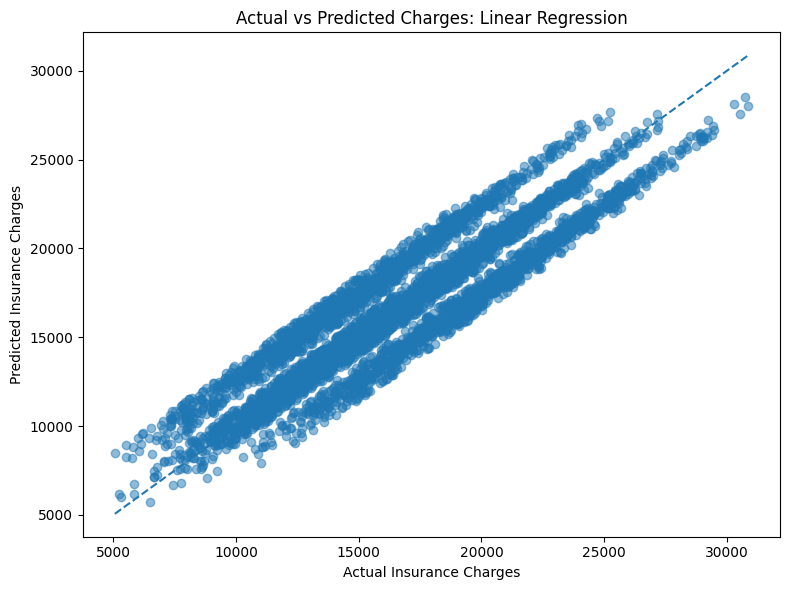

In [55]:
# Plot a sample of test predictions for readability
plot_size = min(5000, len(y_test))

rng = np.random.default_rng(42)

plot_indices = rng.choice(
    len(y_test),
    size=plot_size,
    replace=False
)

actual_sample = y_test.iloc[plot_indices]
predicted_sample = best_model.predict(
    X_test.iloc[plot_indices]
)

plt.figure(figsize=(8, 6))

plt.scatter(
    actual_sample,
    predicted_sample,
    alpha=0.5
)

# Reference line: perfect predictions
lower = min(
    actual_sample.min(),
    predicted_sample.min()
)

upper = max(
    actual_sample.max(),
    predicted_sample.max()
)

plt.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--"
)

plt.xlabel("Actual Insurance Charges")
plt.ylabel("Predicted Insurance Charges")
plt.title(f"Actual vs Predicted Charges: {best_model_name}")

plt.tight_layout()
plt.show()

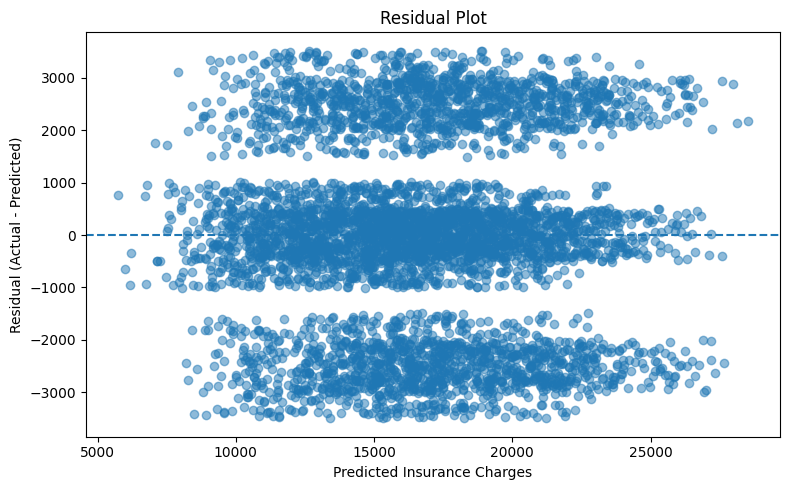

In [56]:
residuals = y_test.iloc[plot_indices] - predicted_sample

plt.figure(figsize=(8, 5))

plt.scatter(
    predicted_sample,
    residuals,
    alpha=0.5
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Insurance Charges")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Residual Plot")

plt.tight_layout()
plt.show()

In [58]:
import os
import pickle

# Create the models folder
os.makedirs("models", exist_ok=True)

# Dynamically assign the best metrics based on the best model
if best_model_name == "Linear Regression":
    best_mae = linear_mae
    best_mse = linear_mse
    best_rmse = linear_rmse
    best_r2 = linear_r2
else:
    best_mae = rf_mae
    best_mse = rf_mse
    best_rmse = rf_rmse
    best_r2 = rf_r2

# Extract unique categories and default numerical medians from the dataset
category_options = {
    col: df[col].dropna().unique().tolist()
    for col in categorical_features
}

numeric_defaults = {
    col: float(df[col].median())
    for col in numerical_features
}

# Save the trained model and its required information as a PKL file
model_bundle = {
    "model": best_model,
    "model_name": best_model_name,
    "feature_columns": X.columns.tolist(),
    "numerical_features": numerical_features,
    "categorical_features": categorical_features,
    "category_options": category_options,
    "numeric_defaults": numeric_defaults,
    "target": target,
    "metrics": {
        "MAE": best_mae,
        "MSE": best_mse,
        "RMSE": best_rmse,
        "R2 Score": best_r2
    }
}

with open("models/insurance_regression_model.pkl", "wb") as file:
    pickle.dump(model_bundle, file)

print("PKL file saved successfully!")
print("File path: models/insurance_regression_model.pkl")

PKL file saved successfully!
File path: models/insurance_regression_model.pkl


In [59]:
import os
import pickle

pkl_path = "models/insurance_regression_model.pkl"

if os.path.exists(pkl_path):
    with open(pkl_path, "rb") as file:
        loaded_model = pickle.load(file)

    print("PKL file exists and loaded successfully!")
    print("Model:", loaded_model["model_name"])
else:
    print("PKL file was not created.")

PKL file exists and loaded successfully!
Model: Linear Regression
